In [1]:
# Load the protocol and define the degradation experiment configuration

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_lfw_people

random_seed = 42

lfw = fetch_lfw_people(
    min_faces_per_person=5,
    color=True,
    resize=1.0,
    download_if_missing=True
)

images = lfw.images
labels = lfw.target
identity_names = lfw.target_names

data_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/data"
)

results_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/results"
)

degraded_images_directory = Path(
    "/content/drive/MyDrive/Colab Notebooks/face_degradation/data/degraded_probes"
)

degraded_images_directory.mkdir(
    parents=True,
    exist_ok=True
)

split_path = data_directory / "lfw_gallery_probe_split.csv"
gallery_probe_split = pd.read_csv(split_path)

gallery_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "gallery"
].copy()

probe_metadata = gallery_probe_split[
    gallery_probe_split["split"] == "probe"
].copy()

gallery_indices = gallery_metadata["image_index"].to_numpy()
probe_indices = probe_metadata["image_index"].to_numpy()

gallery_images = images[gallery_indices]
probe_images = images[probe_indices]

probe_identity_ids = probe_metadata[
    "identity_id"
].to_numpy()

severity_levels = {
    "mild": 1,
    "moderate": 2,
    "severe": 3
}

print(f"Gallery images: {gallery_images.shape}")
print(f"Probe images: {probe_images.shape}")
print(f"Severity levels: {list(severity_levels)}")

Gallery images: (1269, 125, 94, 3)
Probe images: (846, 125, 94, 3)
Severity levels: ['mild', 'moderate', 'severe']


In [2]:
# Define controlled image-degradation operators

def ensure_valid_image(image):
    return np.clip(image, 0.0, 1.0).astype(np.float32)


def apply_blur(image, severity):
    parameters = {
        "mild": (5, 1.0),
        "moderate": (9, 2.5),
        "severe": (15, 4.0)
    }

    kernel_size, sigma = parameters[severity]

    degraded = cv2.GaussianBlur(
        image,
        (kernel_size, kernel_size),
        sigmaX=sigma,
        sigmaY=sigma
    )

    return ensure_valid_image(degraded)


def apply_jpeg_compression(image, severity):
    quality_levels = {
        "mild": 60,
        "moderate": 30,
        "severe": 10
    }

    quality = quality_levels[severity]

    image_uint8 = np.clip(
        image * 255,
        0,
        255
    ).astype(np.uint8)

    image_bgr = cv2.cvtColor(
        image_uint8,
        cv2.COLOR_RGB2BGR
    )

    success, encoded_image = cv2.imencode(
        ".jpg",
        image_bgr,
        [cv2.IMWRITE_JPEG_QUALITY, quality]
    )

    if not success:
        raise RuntimeError("JPEG encoding failed.")

    decoded_bgr = cv2.imdecode(
        encoded_image,
        cv2.IMREAD_COLOR
    )

    decoded_rgb = cv2.cvtColor(
        decoded_bgr,
        cv2.COLOR_BGR2RGB
    )

    return ensure_valid_image(decoded_rgb / 255.0)


def apply_resolution_reduction(image, severity):
    scale_levels = {
        "mild": 0.75,
        "moderate": 0.50,
        "severe": 0.25
    }

    scale = scale_levels[severity]

    height, width = image.shape[:2]

    reduced_width = max(2, int(width * scale))
    reduced_height = max(2, int(height * scale))

    reduced = cv2.resize(
        image,
        (reduced_width, reduced_height),
        interpolation=cv2.INTER_AREA
    )

    restored = cv2.resize(
        reduced,
        (width, height),
        interpolation=cv2.INTER_LINEAR
    )

    return ensure_valid_image(restored)


def apply_illumination_change(image, severity):
    parameters = {
        "mild": (0.85, 0.02),
        "moderate": (0.65, 0.02),
        "severe": (0.45, 0.01)
    }

    brightness_scale, brightness_offset = parameters[severity]

    degraded = (
        image * brightness_scale
        + brightness_offset
    )

    return ensure_valid_image(degraded)


def apply_gaussian_noise(image, severity):
    noise_levels = {
        "mild": 0.025,
        "moderate": 0.060,
        "severe": 0.110
    }

    noise_standard_deviation = noise_levels[severity]

    random_generator = np.random.default_rng(
        random_seed
    )

    noise = random_generator.normal(
        loc=0.0,
        scale=noise_standard_deviation,
        size=image.shape
    )

    degraded = image + noise

    return ensure_valid_image(degraded)


degradation_functions = {
    "blur": apply_blur,
    "jpeg_compression": apply_jpeg_compression,
    "resolution_reduction": apply_resolution_reduction,
    "illumination": apply_illumination_change,
    "gaussian_noise": apply_gaussian_noise
}

print(
    "Degradation operators:",
    list(degradation_functions)
)

Degradation operators: ['blur', 'jpeg_compression', 'resolution_reduction', 'illumination', 'gaussian_noise']


In [3]:
# Define the degradation experiment matrix

degradation_parameters = pd.DataFrame({
    "degradation": [
        "blur",
        "jpeg_compression",
        "resolution_reduction",
        "illumination",
        "gaussian_noise"
    ],
    "mild_setting": [
        "5×5 kernel, sigma=1.0",
        "JPEG quality=60",
        "75% resolution",
        "0.85× brightness",
        "sigma=0.025"
    ],
    "moderate_setting": [
        "9×9 kernel, sigma=2.5",
        "JPEG quality=30",
        "50% resolution",
        "0.65× brightness",
        "sigma=0.060"
    ],
    "severe_setting": [
        "15×15 kernel, sigma=4.0",
        "JPEG quality=10",
        "25% resolution",
        "0.45× brightness",
        "sigma=0.110"
    ]
})

display(degradation_parameters)

,degradation,mild_setting,moderate_setting,severe_setting
0,blur,"5×5 kernel, sigma=1.0","9×9 kernel, sigma=2.5","15×15 kernel, sigma=4.0"
1,jpeg_compression,JPEG quality=60,JPEG quality=30,JPEG quality=10
2,resolution_reduction,75% resolution,50% resolution,25% resolution
3,illumination,0.85× brightness,0.65× brightness,0.45× brightness
4,gaussian_noise,sigma=0.025,sigma=0.060,sigma=0.110


In [4]:
# Apply every severe degradation to one representative probe

example_probe = probe_images[0]

visualization_images = {
    "Original": example_probe
}

for degradation_name, degradation_function in (
    degradation_functions.items()
):
    visualization_images[
        degradation_name.replace("_", " ").title()
    ] = degradation_function(
        example_probe,
        "severe"
    )

print(
    f"Visualized degradations: "
    f"{len(visualization_images)}"
)

Visualized degradations: 6


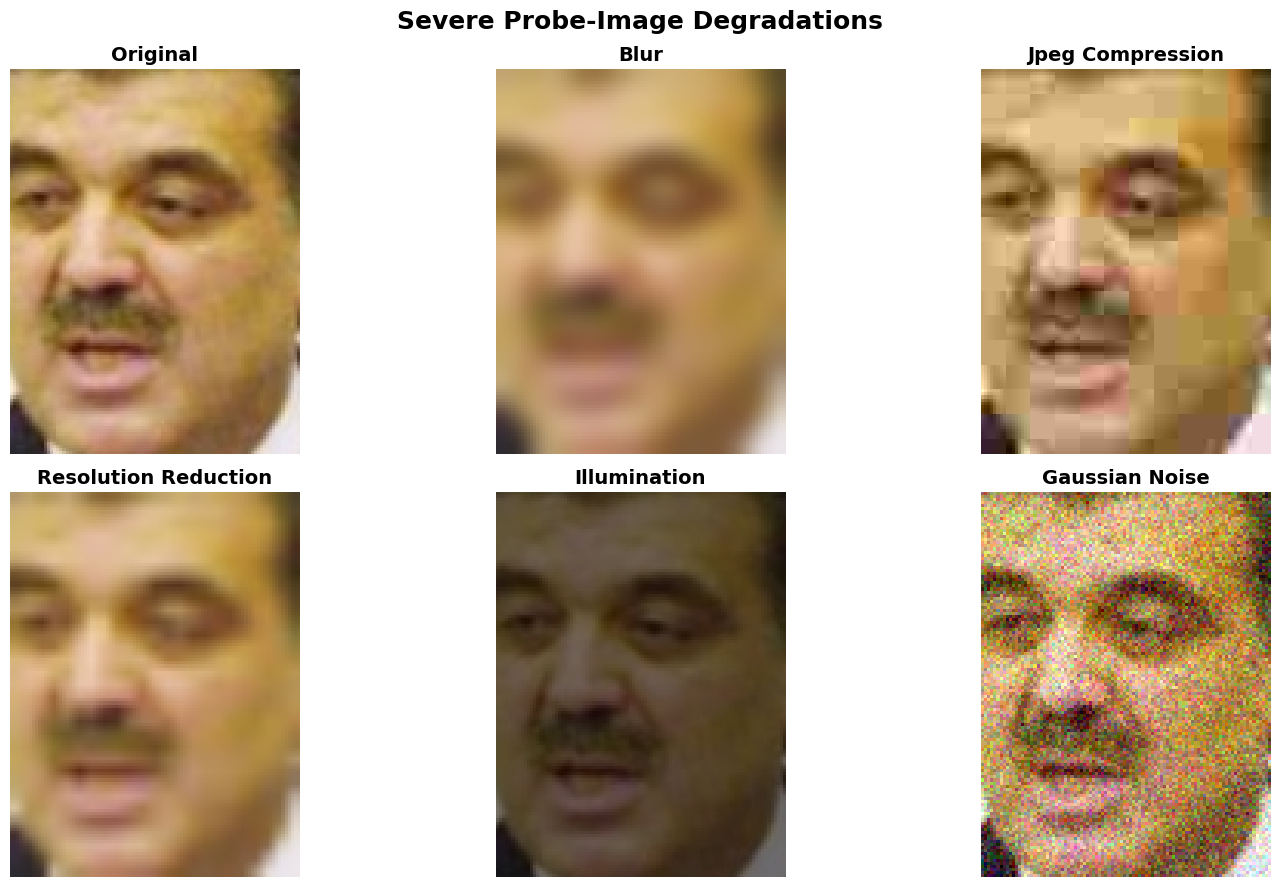

In [5]:
# Visualize the severe degradation examples

figure, axes = plt.subplots(
    2,
    3,
    figsize=(16, 9)
)

axes = axes.ravel()

for axis, (title, image) in zip(
    axes,
    visualization_images.items()
):
    axis.imshow(image)
    axis.set_title(
        title,
        fontsize=14,
        fontweight="bold"
    )
    axis.axis("off")

for axis in axes[len(visualization_images):]:
    axis.axis("off")

figure.suptitle(
    "Severe Probe-Image Degradations",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [6]:
# Save the degradation visualization for later reports

visualization_path = (
    results_directory / "degradation_visualization.png"
)

figure.savefig(
    visualization_path,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"Saved visualization to: "
    f"{visualization_path}"
)

Saved visualization to: /content/drive/MyDrive/Colab Notebooks/face_degradation/results/degradation_visualization.png
